In [1]:
import pandas as np
import numpy as np
import h5py

In [2]:
# load results of model simulations
systole = h5py.File('systole.jld', 'r')
systole = np.asarray(systole['systole'])
diastole = h5py.File('diastole.jld', 'r')
diastole = np.asarray(diastole['diastole'])

In [3]:
# assuming subjects respond integrated when percept integrated 
# for more than half the trial....
delta = (systole > .5).mean() / (diastole > .5).mean() 
print('Prop. of trials in which subject perceives coherent percept reduced by %.01f%%.'%(100*(1-delta)))

Prop. of trials in which subject perceives coherent percept reduced by 15.4%.


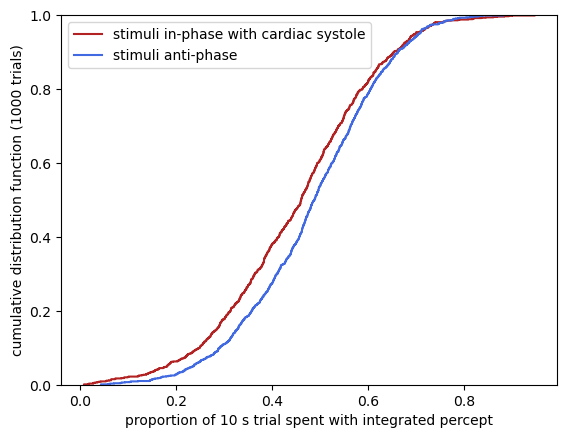

In [4]:
from matplotlib import pyplot as plt
from seaborn import ecdfplot

ax = plt.subplot()
ecdfplot(systole, ax = ax, color = 'firebrick')
ecdfplot(diastole, ax = ax, color = 'royalblue')
plt.plot([], [], color = 'firebrick', label = 'stimuli in-phase with cardiac systole')
plt.plot([], [], color = 'royalblue', label = 'stimuli anti-phase')
plt.legend()
plt.xlabel('proportion of 10 s trial spent with integrated percept')
plt.ylabel('cumulative distribution function (%d trials)'%systole.size)
plt.show()

In [5]:
from  statsmodels.stats.power import tt_solve_power
from pingouin import compute_effsize

def compute_effect_size(seed = None, n_per_sub = 50):
    rng = np.random.default_rng(seed)
    idx = rng.choice(np.arange(systole.size), systole.size)
    syst = systole[idx] # bootstrap from simulations
    # segment trials into hypothetical "subjects" and avg w/i subs
    syst = syst.reshape(systole.size//n_per_sub, n_per_sub).mean(1)
    dias = diastole[idx]
    dias = dias.reshape(systole.size//n_per_sub, n_per_sub).mean(1)
    # return paired difference between systole & diastole conditions
    return compute_effsize(dias, syst, paired = True)

# boostrap 1000 samples
ds = [compute_effect_size(seed) for seed in range(1000)]
print(np.mean(ds)) # this is pretty high, so we'll pick a smaller one

1.5030753264206627


In [6]:
# calculate sample size using smallest effect size of interest
power = 0.95
d = np.quantile(ds, .05/2) # bottom of 95% CI is SESOI
n = tt_solve_power(effect_size = d, power = power, alpha = .05)
print('%.02f power is acheived with %d subjects at d = %.03f'%(power, n, d))

0.95 power is acheived with 20 subjects at d = 0.843
